# 99 · Comparaison des métaheuristiques

Toutes les métaheuristiques du projet, sur toutes les instances, dans les mêmes conditions : même budget $B$ de vraies évaluations, mêmes graines $g = 1, \dots, G$.

**Mesures.** Pour l'algorithme $a$ et l'instance $p$, on note $b^{(g)}_{a,p}$ la meilleure valeur de $f$ trouvée avec la graine $g$, et $\bar b_{a,p} = \frac1G \sum_g b^{(g)}_{a,p}$ sa moyenne.

| Mesure | Définition | Lecture |
|---|---|---|
| tableau | $\bar b_{a,p} \pm \mathrm{écart\text{-}type}$ (meilleur $\min_g b^{(g)}_{a,p}$) | qualité et régularité |
| gain | $100\,\big(\bar b_{\mathrm{id},p} - \bar b_{a,p}\big) / \bar b_{\mathrm{id},p}$ | en %, comparable entre instances |
| rang | rang de $\bar b_{a,p}$ parmi les algorithmes, puis moyenne sur $p$ | classement global |
| victoires | nombre d'instances où le test de Mann-Whitney donne $a$ meilleur que $a'$ avec $p < 0{,}05$ | domination fiable (définition du test : notebook 04) |
| profil de performance | $\rho_a(\tau) = \frac{1}{\lvert P \rvert} \big\lvert \lbrace p : \bar b_{a,p} \le \tau \min_{a'} \bar b_{a',p} \rbrace \big\rvert$ | part des instances où $a$ est à moins de $\tau$ fois la meilleure moyenne |
| convergence | $t \mapsto$ moyenne sur $g$ de $b^{(g)}_t$ | vitesse d'apprentissage |

**Ajouter une métaheuristique.**
1. Créer son module dans `optimizer/algorithms/` et l'ajouter à `optimizer/algorithms/__init__.py`.
2. L'importer ci-dessous et ajouter une ligne dans `CONTENDERS`.
3. Relancer le notebook : seule la nouvelle est calculée. Les exécutions sont enregistrées par algorithme dans `results/comparison/<nom>.jsonl`, et recalculées automatiquement si ses paramètres changent.

In [1]:
import json
import os

import numpy as np
import pandas as pd
from scipy import stats  # test statistique de Mann-Whitney

from goc.paths import RESULTS_ROOT, SOLUTIONS_ROOT
from optimizer import Problem, available_instances, history_frame, load_instance, load_results, results_frame, run_grid, save_results, write_solution_if_better
# Une ligne d'import par famille de métaheuristiques (ajouter ici les nouvelles).
from optimizer.algorithms import identity, random_search, surrogate_filtered
from optimizer.algorithms import ant_colony
from optimizer.algorithms import grasp
from optimizer.algorithms import genetic

In [2]:
# Réglages communs des graphiques : couleurs, polices, grilles.
import matplotlib as mpl
import matplotlib.pyplot as plt

# Palette de couleurs utilisée pour les séries (une couleur par algorithme ou par instance).
PALETTE = ["#3d72c4", "#d4692b", "#2a8a4f", "#c9443c", "#7a5cc2", "#8a8f98", "#c48a0a", "#2a9fb0", "#b04a8f"]
# Couleurs du cours : orange pour les qubits logiques, bleu pour les qubits physiques.
LOGICAL, LOGICAL_SOFT = "#d4692b", "#fdefe6"
PHYSICAL, PHYSICAL_SOFT = "#3d72c4", "#dfe8f5"
# Couleur selon la distance sur la puce : vert = voisins, jaune = distance 2, rouge = distance 3 ou plus.
DISTANCE_COLORS = {1: "#2a8a4f", 2: "#c48a0a", 3: "#c9443c"}
# Gris pour les textes secondaires et les grilles.
MUTED, GRID = "#656d76", "#e1e4e8"

# Application du style à tous les graphiques matplotlib du notebook.
mpl.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def subplot_grid(count, cols=3, width=4.4, height=3.0):
    """Crée une grille de `count` petits graphiques (cols par ligne) et cache les cases inutilisées."""
    # Nombre de lignes nécessaires (division arrondie au supérieur).
    rows = -(-count // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * width, rows * height), squeeze=False)
    # Les cases en trop (dernière ligne incomplète) sont masquées.
    for ax in axes.ravel()[count:]:
        ax.set_visible(False)
    return fig, axes.ravel()[:count]

## Paramètres

Changer `BUDGET`, `SEEDS` ou `COMPARISON_INSTANCES` invalide toutes les exécutions enregistrées : elles sont alors recalculées.

In [3]:
# Nombre de vraies évaluations par exécution.
BUDGET = 200
# Graines : une exécution indépendante par graine, pour chaque métaheuristique et chaque instance.
SEEDS = [0, 1, 2, 3, 4]
# Instances comparées : toutes celles disponibles.
COMPARISON_INSTANCES = available_instances()
# Nombre de processus en parallèle pour les nouveaux calculs.
WORKERS = max(1, (os.cpu_count() or 2) - 4)
# Noms des métaheuristiques à recalculer de force (ensemble vide = relire tout ce qui existe).
RECOMPUTE = set()
# Dossier des exécutions de ce notebook (un fichier par métaheuristique).
CACHE_DIR = RESULTS_ROOT / "comparison"
# Exécutions des notebooks 04, 05 et 06, importées si elles correspondent (même nom, mêmes paramètres, même budget).
LEGACY_SOURCES = [RESULTS_ROOT / "ant_colony" / "comparison.jsonl", RESULTS_ROOT / "grasp" / "comparison.jsonl", RESULTS_ROOT / "genetic" / "comparison.jsonl"]
# Nombre de réévaluations des meilleures solutions (dernière section).
REEVALUATIONS = 10
# Nom du groupe pour les fichiers solutions, et dossier où ils sont écrits.
GROUP = "Groupe0"
SOLUTIONS_DIR = SOLUTIONS_ROOT

## Les algorithmes comparés

Les **références** ne sont pas des métaheuristiques. Une métaheuristique utile doit toutes les battre :
- `identity` : $b_B$ est le minimum de $B$ tirages du bruit autour de $F(\mathrm{id})$ ;
- `random_search` : placements uniformes ;
- `surrogate_filtered` : $\arg\min C$ sur 200 placements aléatoires à chaque évaluation, sans mémoire.

Le détail de chaque métaheuristique est dans son propre notebook (colonies de fourmis : 04, GRASP : 05, algorithme génétique : 06).

In [4]:
# Réglage de référence des fourmis (notebook 04), sans copies de la matrice des phéromones.
# Réglage de GRASP retenu dans le notebook 05 (alpha = 0,1 après l'étude de paramètres).
GRASP_BASE = {"alpha": 0.1, "rcl": "value", "local_search": True, "fitness_patience": 0}
# Réglage de l'algorithme génétique retenu dans le notebook 06 (N = 10 après l'étude de paramètres).
GENETIC_BASE = {"population_size": 10, "selection": "tournament", "tournament_size": 2, "tournament_p": 1.0, "crossover_operator": "pmx",
                "crossover_rate": 0.8, "mutation_rate": 0.1, "construction_genes": False, "initial_candidates": 1, "preselection": 1}
ACO_BASE = {"ants": 30, "evaluated": 5, "alpha": 1.0, "beta": 2.0, "rho": 0.2, "tau_min_ratio": 0.05, "elite_weight": 1.0, "local_search_steps": 0, "snapshot_every": 10**6}

CONTENDERS = {
    "identity": {"family": "reference", "algorithm": identity.run, "params": {}, "description": "placement identité réévalué à chaque évaluation"},
    "random_search": {"family": "reference", "algorithm": random_search.run, "params": {}, "description": "placements aléatoires"},
    "surrogate_filtered": {"family": "reference", "algorithm": surrogate_filtered.run, "params": {"candidates": 200}, "description": "meilleur de 200 placements aléatoires selon le coût de distance"},
    "aco_all": {"family": "ant colony", "algorithm": ant_colony.run, "params": {**ACO_BASE, "ants": 10, "evaluated": 10}, "description": "10 fourmis par itération, toutes évaluées"},
    "aco_filtered": {"family": "ant colony", "algorithm": ant_colony.run, "params": ACO_BASE, "description": "30 fourmis, seules les 5 meilleures selon le coût de distance sont évaluées"},
    "grasp": {"family": "GRASP", "algorithm": grasp.run, "params": GRASP_BASE, "description": "glouton randomisé (alpha = 0,1) + descente sur C jusqu'à l'optimum local, 1 évaluation par itération"},
    "grasp_f": {"family": "GRASP", "algorithm": grasp.run, "params": {**GRASP_BASE, "fitness_patience": 3}, "description": "grasp + descente échantillonnée sur f (arrêt après 3 échecs)"},
    "genetic": {"family": "genetic", "algorithm": genetic.run, "params": GENETIC_BASE, "description": "N = 10, tournoi k = 2, PMX (P_c = 0,8), transposition (P_m = 0,1), remplacement (mu + lambda) sans doublons"},
    "genetic_filtered": {"family": "genetic", "algorithm": genetic.run, "params": {**GENETIC_BASE, "initial_candidates": 200, "preselection": 5}, "description": "genetic + population initiale filtrée par C et présélection de 5N enfants par C"},
}

## Chargement ou calcul

Pour chaque algorithme, dans l'ordre :
1. son fichier `results/comparison/<nom>.jsonl`, s'il contient toutes les exécutions demandées avec les mêmes paramètres ;
2. sinon, les exécutions des notebooks 04, 05 et 06, si elles correspondent ;
3. sinon, un calcul en parallèle.

In [5]:
def params_key(params):
    """Représentation texte stable d'un dictionnaire de paramètres (pour comparer deux réglages)."""
    return json.dumps(params, sort_keys=True, default=str)


def matching_runs(runs, name, params):
    """Exécutions de `name` avec exactement ces paramètres et ce budget, sur les instances et graines demandées (sans doublon)."""
    selected = {}
    for r in runs:
        if r.algorithm == name and params_key(r.params) == params_key(params) and r.evaluations == BUDGET and r.instance_id in COMPARISON_INSTANCES and r.seed in SEEDS:
            # Une seule exécution par couple (instance, graine).
            selected.setdefault((r.instance_id, r.seed), r)
    return list(selected.values())


def is_complete(runs):
    """Vrai si toutes les combinaisons (instance, graine) demandées sont présentes."""
    return {(r.instance_id, r.seed) for r in runs} >= {(i, s) for i in COMPARISON_INSTANCES for s in SEEDS}


# Les fichiers des notebooks 04, 05 et 06 sont lus une seule fois.
legacy_runs = [r for source in LEGACY_SOURCES if source.exists() for r in load_results(source)]


def load_contender(name, spec):
    """Renvoie (exécutions, origine) pour une métaheuristique : cache, import depuis le notebook 04, ou calcul."""
    path = CACHE_DIR / f"{name}.jsonl"
    if path.exists() and name not in RECOMPUTE:
        runs = matching_runs(load_results(path), name, spec["params"])
        if is_complete(runs):
            return runs, "cache"
    if name not in RECOMPUTE:
        runs = matching_runs(legacy_runs, name, spec["params"])
        if is_complete(runs):
            save_results(runs, path)
            return runs, "imported from notebooks 04-06"
    print(f"computing {name} ...")
    runs = run_grid({name: (spec["algorithm"], spec["params"])}, COMPARISON_INSTANCES, SEEDS, BUDGET, workers=WORKERS)
    save_results(runs, path)
    return runs, "computed"


comparison, origins = [], {}
for name, spec in CONTENDERS.items():
    runs, origins[name] = load_contender(name, spec)
    comparison.extend(runs)

# Une ligne par exécution, et l'ordre d'affichage des métaheuristiques.
frame = results_frame(comparison)
ORDER = list(CONTENDERS)
# Tableau récapitulatif des métaheuristiques comparées.
contenders_table = pd.DataFrame([
    {"name": name, "family": spec["family"], "description": spec["description"], "runs": int((frame["algorithm"] == name).sum()), "origin": origins[name], "params": params_key(spec["params"])}
    for name, spec in CONTENDERS.items()
]).set_index("name")
contenders_table

,family,description,runs,origin,params
name,,,,,
identity,reference,placement identité réévalué à chaque évaluation,45,cache,{}
random_search,reference,placements aléatoires,45,cache,{}
surrogate_filtered,reference,meilleur de 200 placements aléatoires selon le...,45,cache,"{""candidates"": 200}"
aco_all,ant colony,"10 fourmis par itération, toutes évaluées",45,cache,"{""alpha"": 1.0, ""ants"": 10, ""beta"": 2.0, ""elite..."
aco_filtered,ant colony,"30 fourmis, seules les 5 meilleures selon le c...",45,cache,"{""alpha"": 1.0, ""ants"": 30, ""beta"": 2.0, ""elite..."
grasp,GRASP,"glouton randomisé (alpha = 0,1) + descente sur...",45,cache,"{""alpha"": 0.1, ""fitness_patience"": 0, ""local_s..."
grasp_f,GRASP,grasp + descente échantillonnée sur f (arrêt a...,45,cache,"{""alpha"": 0.1, ""fitness_patience"": 3, ""local_s..."
genetic,genetic,"N = 10, tournoi k = 2, PMX (P_c = 0,8), transp...",45,imported from notebooks 04-06,"{""construction_genes"": false, ""crossover_opera..."
genetic_filtered,genetic,genetic + population initiale filtrée par C et...,45,imported from notebooks 04-06,"{""construction_genes"": false, ""crossover_opera..."


In [6]:
# Couleurs : une teinte par famille, une nuance par variante (les références en gris).
FAMILY_SHADES = {
    "reference": ["#8a8f98", "#b8bec6", "#5f6670"],
    "ant colony": ["#d4692b", "#e8a06f", "#a8501f", "#f0c4a3"],
    "GRASP": ["#2a8a4f", "#6fbf8e", "#1d6338"],
    "genetic": ["#7a5cc2", "#a993dc", "#5a3f9a"],
}
# Teintes de secours pour les familles ajoutées plus tard.
SPARE_SHADES = [["#2a8a4f", "#6fbf8e", "#1d6338"], ["#7a5cc2", "#a993dc", "#5a3f9a"], ["#c48a0a", "#e0b85a", "#946805"], ["#2a9fb0", "#7cc7d2", "#1d7683"]]


def contender_colors(contenders):
    """Couleur de chaque métaheuristique : la teinte de sa famille, une nuance différente par variante."""
    shades, used, colors = dict(FAMILY_SHADES), {}, {}
    for name, spec in contenders.items():
        family = spec["family"]
        if family not in shades:
            shades[family] = SPARE_SHADES[len([f for f in shades if f not in FAMILY_SHADES]) % len(SPARE_SHADES)]
        index = used.get(family, 0)
        colors[name] = shades[family][index % len(shades[family])]
        used[family] = index + 1
    return colors


COLORS = contender_colors(CONTENDERS)
FAMILIES = {name: spec["family"] for name, spec in CONTENDERS.items()}

## 1. Tableau comparatif

$\bar b_{a,p} \pm$ écart-type (meilleur), sur les graines :

In [7]:
def display_table(frame, value="best_cost"):
    """Tableau lisible : pour chaque algorithme et instance, « moyenne ± écart-type (meilleur) »."""
    cells = frame.groupby(["algorithm", "instance_id"], sort=False)[value].agg(lambda s: f"{s.mean():.1f} ± {s.std(ddof=0):.1f} ({s.min():g})")
    return cells.unstack("instance_id").rename(columns=lambda c: f"inst. {c}")


summary_table = display_table(frame).reindex(ORDER)
summary_table

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9
algorithm,,,,,,,,,
identity,57.0 ± 0.0 (57),59.0 ± 0.0 (59),141.0 ± 0.0 (141),62.0 ± 0.0 (62),332.2 ± 1.0 (331),78.2 ± 2.4 (77),107.0 ± 0.0 (107),66.8 ± 1.0 (66),137.0 ± 0.0 (137)
random_search,38.4 ± 2.1 (36),90.2 ± 4.5 (86),139.4 ± 5.2 (132),42.4 ± 0.8 (42),334.0 ± 9.0 (323),39.6 ± 3.7 (35),73.6 ± 7.2 (63),40.0 ± 3.8 (34),98.2 ± 3.5 (93)
surrogate_filtered,34.8 ± 1.7 (33),75.8 ± 2.9 (71),140.0 ± 2.2 (137),38.8 ± 1.5 (36),332.0 ± 4.9 (326),33.8 ± 2.1 (31),64.6 ± 6.3 (57),38.4 ± 2.4 (34),90.2 ± 10.4 (79)
aco_all,28.6 ± 2.9 (25),59.0 ± 0.0 (59),131.0 ± 3.7 (124),36.2 ± 1.0 (35),324.8 ± 2.9 (320),25.6 ± 1.2 (25),39.8 ± 5.9 (34),25.8 ± 3.9 (22),69.8 ± 6.4 (59)
aco_filtered,30.0 ± 0.9 (29),59.0 ± 0.0 (59),128.0 ± 5.2 (122),33.8 ± 2.4 (30),323.0 ± 4.4 (317),25.0 ± 0.0 (25),25.2 ± 2.9 (22),21.6 ± 2.0 (19),54.4 ± 2.8 (51)
grasp,29.8 ± 1.5 (27),59.0 ± 0.0 (59),136.0 ± 6.6 (127),34.8 ± 1.7 (32),323.4 ± 3.3 (317),25.0 ± 0.0 (25),22.0 ± 0.0 (22),18.0 ± 0.6 (17),50.2 ± 2.9 (48)
grasp_f,29.6 ± 1.2 (28),59.0 ± 0.0 (59),139.2 ± 2.9 (134),35.6 ± 0.5 (35),324.8 ± 3.2 (320),25.0 ± 0.0 (25),23.8 ± 2.4 (22),19.4 ± 0.5 (19),50.0 ± 1.7 (48)
genetic,31.4 ± 2.9 (27),76.8 ± 5.9 (71),132.6 ± 5.7 (124),35.8 ± 1.6 (34),328.4 ± 6.2 (318),36.2 ± 3.1 (31),59.6 ± 8.5 (49),39.8 ± 1.9 (38),79.8 ± 8.8 (68)
genetic_filtered,30.0 ± 0.9 (29),66.2 ± 8.8 (59),131.2 ± 2.8 (128),33.0 ± 1.7 (31),322.2 ± 4.9 (318),31.4 ± 3.6 (27),43.0 ± 7.9 (31),29.0 ± 3.7 (24),67.2 ± 9.2 (51)


## 2. Gains et classement

**Gain par rapport à l'identité**, en %. Positif = meilleur que l'identité.

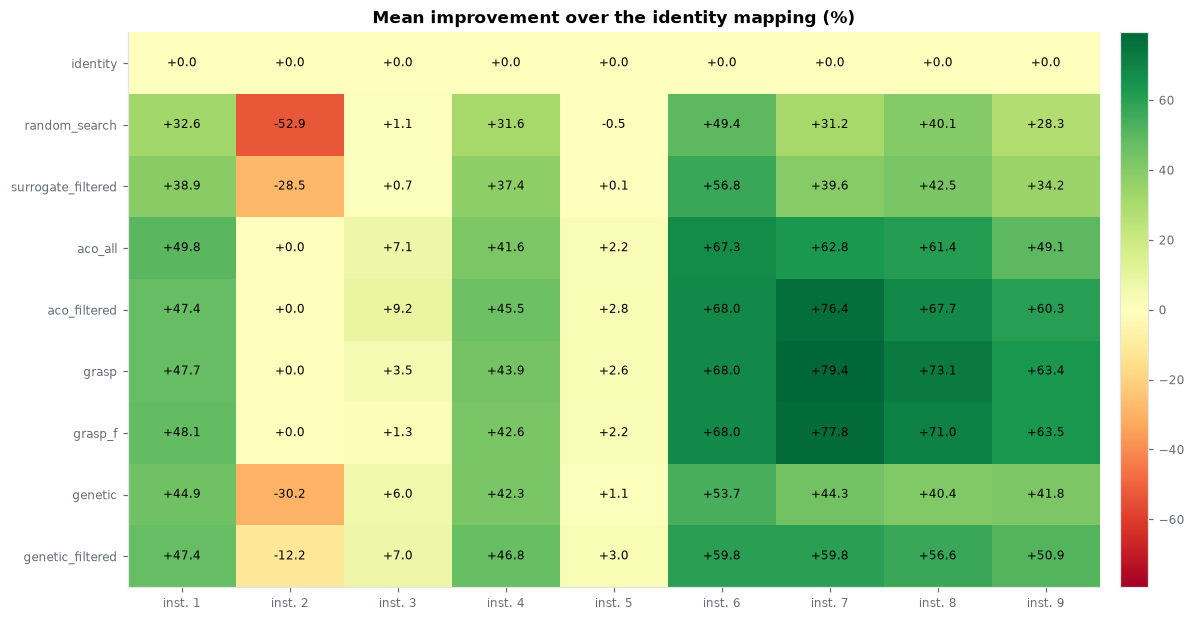

In [8]:
def gain_table(frame, reference="identity"):
    """Gain moyen de chaque algorithme par rapport à la référence, en % : 100 × (référence − algorithme) / référence."""
    means = frame.groupby(["algorithm", "instance_id"])["best_cost"].mean().unstack()
    return (100 * (means.loc[reference] - means) / means.loc[reference]).round(1)


def plot_gain_heatmap(gains):
    """Carte de chaleur des gains : vert = mieux que l'identité, rouge = moins bien."""
    limit = max(5.0, float(np.nanmax(np.abs(gains.values))))
    fig, ax = plt.subplots(figsize=(1.0 * gains.shape[1] + 3, 0.55 * gains.shape[0] + 1.6))
    image = ax.imshow(gains.values, cmap="RdYlGn", vmin=-limit, vmax=limit, aspect="auto")
    for (i, j), value in np.ndenumerate(gains.values):
        ax.text(j, i, f"{value:+.1f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(gains.shape[1]), [f"inst. {c}" for c in gains.columns])
    ax.set_yticks(range(gains.shape[0]), gains.index)
    ax.grid(False)
    ax.set_title("Mean improvement over the identity mapping (%)")
    fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
    return fig


gains = gain_table(frame).reindex(ORDER)
plot_gain_heatmap(gains);

**Rangs** de $\bar b_{a,p}$ sur chaque instance (1 = meilleure ; ex æquo = même rang), puis rang moyen :

In [9]:
means = frame.groupby(["algorithm", "instance_id"])["best_cost"].mean().unstack().reindex(ORDER)
ranks = means.rank(axis=0, method="min").rename(columns=lambda c: f"inst. {c}")
ranks["mean rank"] = ranks.mean(axis=1).round(2)
ranks = ranks.sort_values("mean rank")
ranks

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9,mean rank
algorithm,,,,,,,,,,
grasp,3.0,1.0,5.0,3.0,3.0,1.0,1.0,1.0,2.0,2.22
aco_filtered,4.0,1.0,1.0,2.0,2.0,1.0,3.0,3.0,3.0,2.22
grasp_f,2.0,1.0,6.0,4.0,4.0,1.0,2.0,2.0,1.0,2.56
aco_all,1.0,1.0,2.0,6.0,4.0,4.0,4.0,4.0,5.0,3.44
genetic_filtered,4.0,6.0,3.0,1.0,1.0,5.0,5.0,5.0,4.0,3.78
genetic,6.0,8.0,4.0,5.0,6.0,7.0,6.0,7.0,6.0,6.11
surrogate_filtered,7.0,7.0,8.0,7.0,7.0,6.0,7.0,6.0,7.0,6.89
identity,9.0,1.0,9.0,9.0,8.0,9.0,9.0,9.0,9.0,8.00
random_search,8.0,9.0,7.0,8.0,9.0,8.0,8.0,8.0,8.0,8.11


**Meilleure variante de chaque famille**, instance par instance : $\max_{a \in \text{famille}} \mathrm{gain}_{a,p}$.

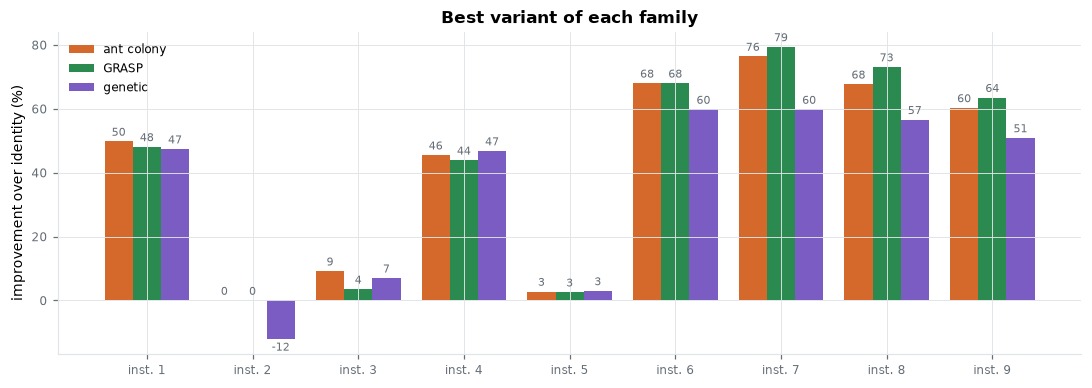

In [10]:
def plot_family_best(gains):
    """Barres groupées : gain de la meilleure variante de chaque famille, par instance."""
    families = [f for f in dict.fromkeys(FAMILIES[name] for name in gains.index) if f != "reference"]
    fig, ax = plt.subplots(figsize=(12, 3.8))
    x = np.arange(gains.shape[1])
    width = 0.8 / max(len(families), 1)
    for k, family in enumerate(families):
        members = [name for name in gains.index if FAMILIES[name] == family]
        values = gains.loc[members].max(axis=0)
        offset = (k - (len(families) - 1) / 2) * width
        bars = ax.bar(x + offset, values, width, color=COLORS[members[0]], label=family)
        ax.bar_label(bars, fmt="%.0f", fontsize=7, color=MUTED, padding=2)
    ax.set_xticks(x, [f"inst. {c}" for c in gains.columns])
    ax.set_ylabel("improvement over identity (%)")
    ax.set_title("Best variant of each family")
    ax.legend()
    return fig


# Utile seulement à partir de deux familles de métaheuristiques (hors références).
if len({f for f in FAMILIES.values() if f != "reference"}) >= 2:
    plot_family_best(gains)
else:
    print("Only one metaheuristic family so far: this plot appears once a second family is added to CONTENDERS.")

## 3. Victoires significatives

Case (ligne $A$, colonne $B$) : nombre d'instances où $A$ est significativement meilleure que $B$ (Mann-Whitney unilatéral sur les $G$ graines, $p < 0{,}05$). Avec $G = 5$, le plus petit $p$ atteignable est $1/\binom{10}{5} \approx 0{,}004$ : le test est prudent, et un 0 ne prouve pas que $A$ est moins bonne.

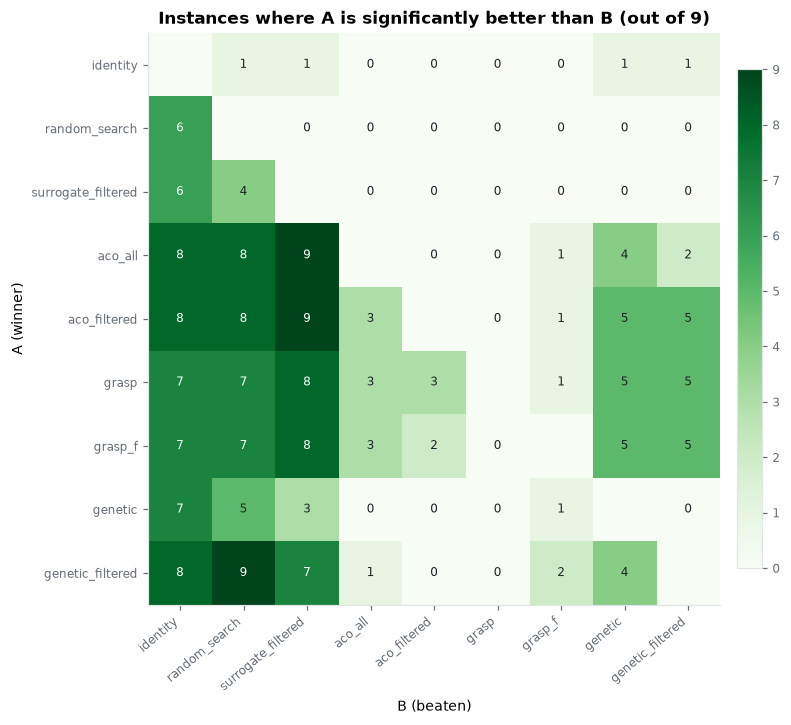

In [11]:
def wins_matrix(frame, order, alpha=0.05):
    """Nombre d'instances où l'algorithme en ligne est significativement meilleur que celui en colonne."""
    wins = pd.DataFrame(0, index=order, columns=order)
    for instance_id in sorted(frame["instance_id"].unique()):
        subset = frame[frame["instance_id"] == instance_id]
        costs = {name: subset.loc[subset["algorithm"] == name, "best_cost"] for name in order}
        for a in order:
            for b in order:
                # Si les deux séries sont identiques et constantes, le test n'a pas de sens : pas de victoire.
                if a != b and not (costs[a].nunique() == 1 and costs[b].nunique() == 1 and costs[a].iloc[0] == costs[b].iloc[0]):
                    if stats.mannwhitneyu(costs[a], costs[b], alternative="less").pvalue < alpha:
                        wins.loc[a, b] += 1
    return wins


def plot_wins(wins):
    """Carte de chaleur de la matrice des victoires significatives."""
    fig, ax = plt.subplots(figsize=(0.75 * len(wins) + 3, 0.55 * len(wins) + 1.8))
    image = ax.imshow(wins.values, cmap="Greens", vmin=0, vmax=len(COMPARISON_INSTANCES))
    for (i, j), value in np.ndenumerate(wins.values):
        if i != j:
            ax.text(j, i, str(value), ha="center", va="center", fontsize=8, color="white" if value > 0.6 * len(COMPARISON_INSTANCES) else "#1f2328")
    ax.set_xticks(range(len(wins)), wins.columns, rotation=40, ha="right")
    ax.set_yticks(range(len(wins)), wins.index)
    ax.set_xlabel("B (beaten)")
    ax.set_ylabel("A (winner)")
    ax.grid(False)
    ax.set_title(f"Instances where A is significantly better than B (out of {len(COMPARISON_INSTANCES)})")
    fig.colorbar(image, ax=ax, fraction=0.03, pad=0.02)
    return fig


wins = wins_matrix(frame, ORDER)
plot_wins(wins);

## 4. Profil de performance

Pour chaque instance, on calcule le rapport $r_{a,p} = \bar b_{a,p} / \min_{a'} \bar b_{a',p} \ge 1$, puis

$$
\rho_a(\tau) = \frac{1}{\lvert P \rvert} \big\lvert \lbrace p \in P : r_{a,p} \le \tau \rbrace \big\rvert
$$

- $\rho_a(1)$ : part des instances où $a$ est la meilleure.
- $\tau$ minimal tel que $\rho_a(\tau) = 1$ : l'écart maximal de $a$ à la meilleure.

Une courbe haute et à gauche désigne un algorithme bon partout, pas seulement en moyenne.

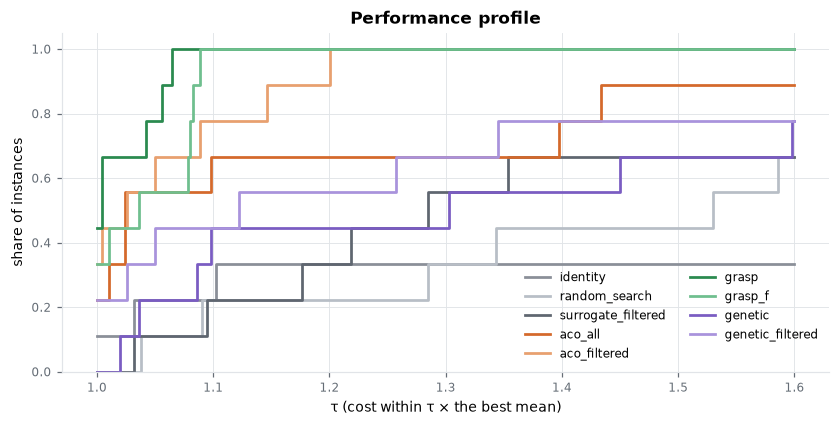

In [12]:
def plot_performance_profile(means, max_ratio=1.6):
    """Profil de performance (Dolan-Moré) calculé sur les moyennes par instance."""
    ratios = means / means.min(axis=0)
    taus = np.linspace(1, max_ratio, 300)
    fig, ax = plt.subplots(figsize=(9, 4))
    for name in means.index:
        share = [(ratios.loc[name] <= tau).mean() for tau in taus]
        ax.step(taus, share, where="post", color=COLORS[name], linewidth=1.8, label=name)
    ax.set_xlabel("τ (cost within τ × the best mean)")
    ax.set_ylabel("share of instances")
    ax.set_ylim(0, 1.05)
    ax.set_title("Performance profile")
    ax.legend(loc="lower right", ncol=2)
    return fig


plot_performance_profile(means);

## 5. Convergence

Moyenne sur les graines de $b_t$, le meilleur $f$ après $t$ évaluations. Une courbe encore descendante à $t = B$ signale qu'un budget plus grand aiderait.

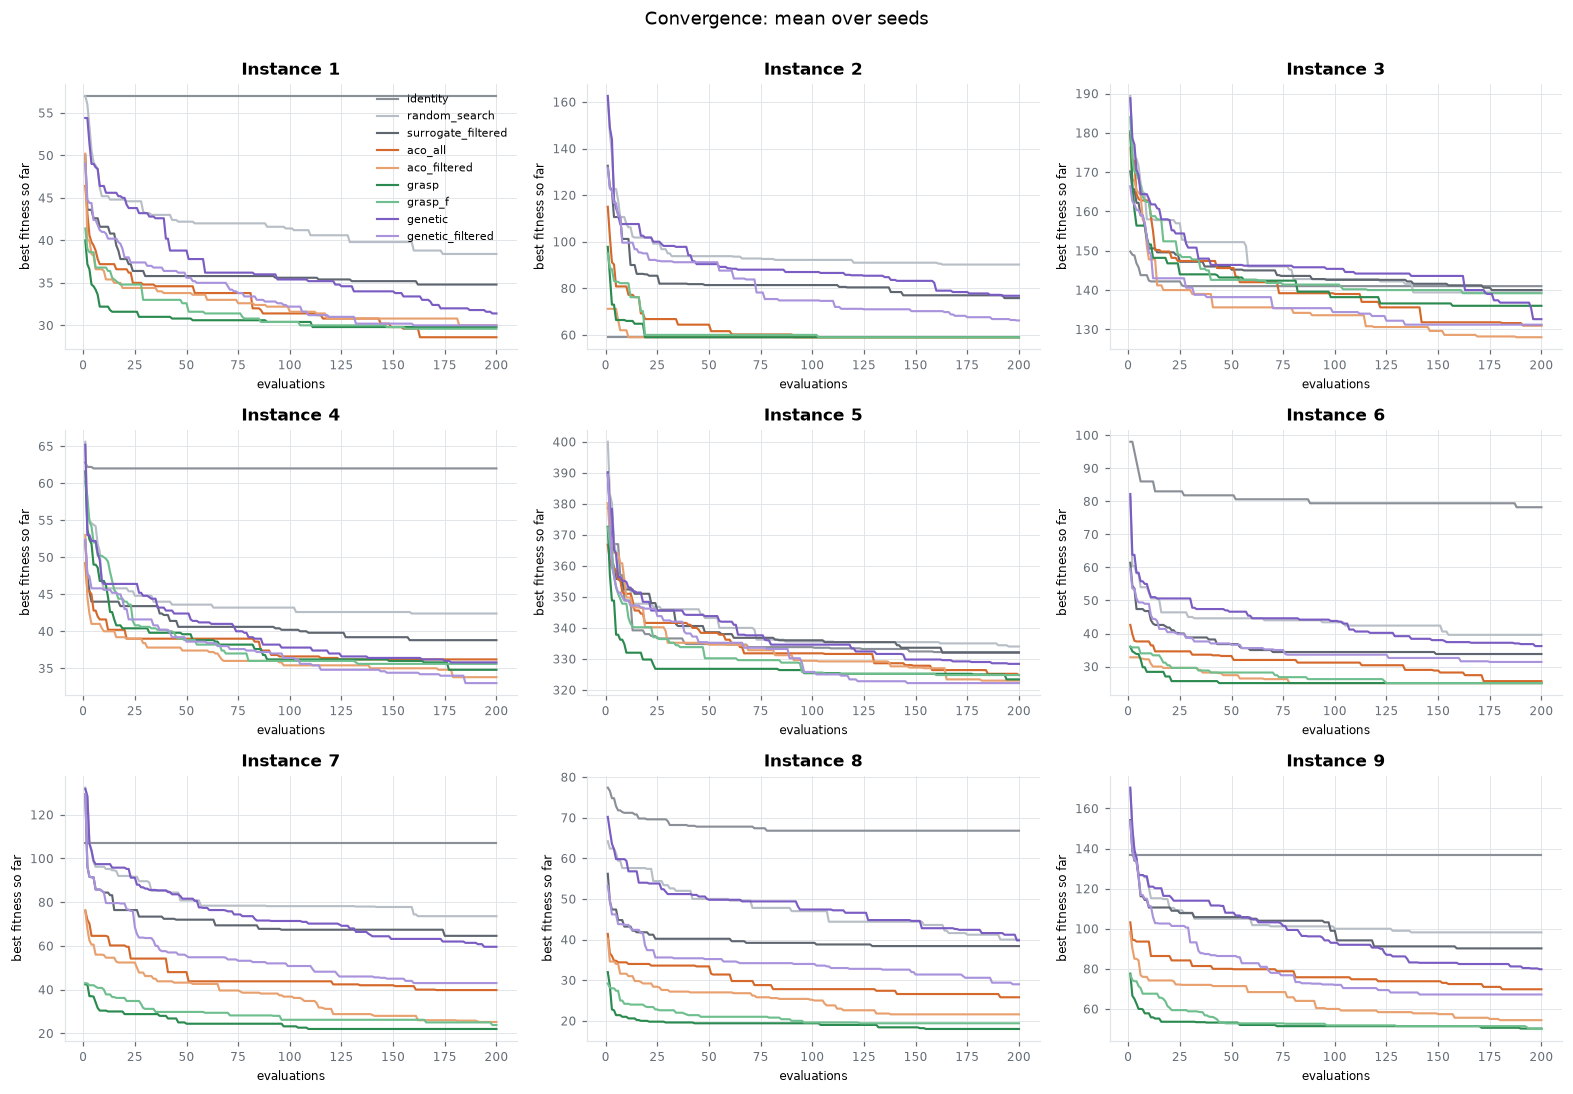

In [13]:
def plot_convergence(results, order):
    """Courbes de convergence de chaque métaheuristique sur chaque instance (moyenne sur les graines)."""
    history = history_frame(results)
    instance_ids = sorted(history["instance_id"].unique())
    fig, axes = subplot_grid(len(instance_ids), cols=3, width=4.8, height=3.3)
    for ax, instance_id in zip(axes, instance_ids):
        subset = history[history["instance_id"] == instance_id]
        for name in order:
            curves = subset[subset["algorithm"] == name].pivot_table(index="evaluation", columns="seed", values="best").ffill()
            ax.plot(curves.index, curves.mean(axis=1), color=COLORS[name], label=name, linewidth=1.4)
        ax.set_title(f"Instance {instance_id}")
        ax.set_xlabel("evaluations", fontsize=8)
        ax.set_ylabel("best fitness so far", fontsize=8)
    axes[0].legend(fontsize=7)
    fig.suptitle("Convergence: mean over seeds", y=1.0)
    fig.tight_layout()
    return fig


plot_convergence(comparison, ORDER);

**Temps moyen d'une exécution** (en secondes ; presque tout le temps est passé dans `fitness_inner`, et la charge de la machine peut différer entre exécutions) :

In [14]:
run_times = frame.groupby(["algorithm", "instance_id"])["seconds"].mean().unstack().reindex(ORDER).round(1).rename(columns=lambda c: f"inst. {c}")
run_times

instance_id,inst. 1,inst. 2,inst. 3,inst. 4,inst. 5,inst. 6,inst. 7,inst. 8,inst. 9
algorithm,,,,,,,,,
identity,32.1,109.8,58.8,30.5,78.7,42.4,44.7,51.0,47.5
random_search,34.1,158.0,72.5,37.5,92.6,47.9,52.3,56.2,55.2
surrogate_filtered,31.1,139.1,59.3,29.7,80.9,40.9,43.1,48.6,51.7
aco_all,32.5,137.8,63.7,33.2,86.5,45.1,41.3,43.5,42.7
aco_filtered,32.1,133.8,59.3,37.8,95.2,45.7,40.8,48.9,47.0
grasp,15.3,130.6,47.9,14.4,63.5,19.8,17.9,23.1,22.2
grasp_f,15.5,130.8,47.7,14.2,62.8,19.5,17.6,22.2,19.2
genetic,16.5,133.7,49.3,15.0,64.3,22.7,30.2,34.4,35.0
genetic_filtered,16.2,131.5,48.3,14.7,64.3,21.8,22.1,30.4,25.9


## 6. Meilleures solutions connues

Pour chaque instance : la meilleure exécution, tous algorithmes confondus, réévaluée `REEVALUATIONS` fois pour estimer $F(s^\star)$, et l'algorithme le meilleur **en moyenne**. Le fichier `GROUP_Challenge_N.txt` n'est écrit que s'il bat celui déjà présent dans `solutions/`.

In [15]:
rows = []
for instance_id in COMPARISON_INSTANCES:
    # Meilleure exécution sur cette instance, toutes métaheuristiques et graines confondues.
    best = min((r for r in comparison if r.instance_id == instance_id), key=lambda r: r.best_cost)
    checks = Problem(load_instance(instance_id)).fitness_samples(best.best_mapping, REEVALUATIONS)
    cost = min(best.best_cost, min(checks))
    path, written, previous = write_solution_if_better(best.best_mapping, cost, instance_id, group=GROUP, directory=SOLUTIONS_DIR)
    rows.append({
        "instance": instance_id,
        "best on average": means[instance_id].idxmin(),
        "best single run": f"{best.algorithm} (seed {best.seed})",
        "cost during search": best.best_cost,
        "re-evaluation mean": round(float(np.mean(checks)), 2),
        "re-evaluation std": round(float(np.std(checks)), 2),
        "file status": "written" if written else f"kept (existing cost {previous:g})",
        "mapping": " ".join(map(str, best.best_mapping)),
    })
best_known = pd.DataFrame(rows).set_index("instance")
best_known

,best on average,best single run,cost during search,re-evaluation mean,re-evaluation std,file status,mapping
instance,,,,,,,
1,aco_all,aco_all (seed 2),25,28.6,2.37,kept (existing cost 25),0 14 13 2 12 3 11 15 4 10 5 1
2,identity,identity (seed 0),59,59.0,0.00,kept (existing cost 59),0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15
3,aco_filtered,aco_filtered (seed 0),122,140.8,7.63,kept (existing cost 115),6 9 10 7 12 3 4 11 8 5
4,genetic_filtered,aco_filtered (seed 3),30,30.9,1.37,kept (existing cost 30),7 8 12 6 1 16 14 4 13 2 10 18 11 3 0 19 9 5 17
5,genetic_filtered,aco_filtered (seed 1),317,335.5,7.65,kept (existing cost 316),5 6 8 7 16 17 11 14 10 12 13 18
6,aco_filtered,aco_all (seed 0),25,25.0,0.00,kept (existing cost 25),1 13 8 3 11 10 5 16 9 14 6 2 18 7
7,grasp,aco_filtered (seed 0),22,22.0,0.00,kept (existing cost 22),9 8 5 3 2 1 4 7 12 10 13 14 16 19 22 24 25 23 ...
8,grasp,grasp (seed 1),17,18.9,2.07,kept (existing cost 17),22 19 18 21 14 13 1 2 25 24 23 3 17 12 15 0 26...
9,grasp_f,grasp (seed 1),48,50.4,1.80,kept (existing cost 48),6 12 13 14 11 8 5 3 2 1 4 7 10 15 18 17 21 23 ...


## État actuel (22/11/2026)

_À mettre à jour à chaque nouvelle métaheuristique. Comparaison de 9 algorithmes (3 références, 2 colonies de fourmis, 2 GRASP, 2 algorithmes génétiques), $B = 200$, 5 graines, 9 instances._

| Rang moyen | Algorithme | Famille | Instances à ≤ 5 % de la meilleure moyenne | Pire rapport $r_{a,p}$ |
|---|---|---|---|---|
| 2,22 | `grasp` | GRASP | 7 / 9 | 1,06 |
| 2,22 | `aco_filtered` | colonies de fourmis | 6 / 9 | 1,20 |
| 2,56 | `grasp_f` | GRASP | 5 / 9 | 1,09 |
| 3,44 | `aco_all` | colonies de fourmis | 5 / 9 | 1,81 |
| 3,78 | `genetic_filtered` | algorithme génétique | 4 / 9 | 1,95 |
| 6,11 | `genetic` | algorithme génétique | 2 / 9 | 2,71 |
| 6,89 | `surrogate_filtered` | référence | 1 / 9 | 2,94 |
| 8,00 | `identity` | référence | 2 / 9 | 4,86 |
| 8,11 | `random_search` | référence | 1 / 9 | 3,35 |

- **`grasp` et `aco_filtered` sont à égalité en rang moyen.** `grasp` est la plus régulière : son pire écart à la meilleure moyenne est de 6 %. Il bat significativement `aco_filtered` sur 7, 8 et 9, l'inverse n'arrivant sur aucune instance.
- **Les méthodes constructives dominent là où $C$ est fiable** (2, 6 à 9) : construire avec le coût ajouté $g_t$ donne une avance que l'algorithme génétique ne rattrape pas en 19 générations.
- **Là où $C$ guide mal** (3, 4, 5), les familles se valent : `aco_filtered` est 1re sur 3, `genetic_filtered` sur 4 et 5, sans différence significative.
- **L'utilisation gratuite de $C$ est décisive pour toutes les familles** :
  - `aco_filtered` est meilleure que `aco_all` ;
  - `genetic_filtered` est meilleure que `genetic` ;
  - la recherche locale sur $C$ de GRASP.
- **Meilleures solutions connues** (dans `solutions/`) :
  - GRASP détient celles des instances 3 (115) et 9 (48), et égale les fourmis sur 7 (22) et 8 (17) ;
  - les fourmis, celles des instances 1, 4, 5 et 6 ;
  - sur l'instance 2, l'identité est déjà au niveau optimal présumé (59) ;
  - l'algorithme génétique n'a établi aucun record.